# AIP304 Coursework 2 | Option 2 | Lesion supervision pilot

Can lesion supervision improve rejection of unseen diseases on familiar plant hosts while preserving classification of known diseases?

This notebook audits PlantSeg v7 and compares a ResNet-18 baseline with a lesion-supervised ResNet-18 on assignment A using seed 42. The pilot uses the validation partition.

The prespecified practical target for the full experiment is a familiar-host AUOSCR gain of at least 0.02 in each assignment, with a positive difference in at least two of three paired seeds and a known-class macro-F1 reduction of at most 0.02 in each assignment. This tolerance limits the acceptable loss in known-class recognition. One validation pair provides evidence for the pilot only.

## 1. Environment and dataset

Select the project Python interpreter in PyCharm. The notebook uses `torch`, `torchvision`, `Pillow`, `numpy`, and `matplotlib`. Local validation used Python 3.9.6, PyTorch 2.8.0, and torchvision 0.23.0 on Apple Silicon.

Download [PlantSeg v7](https://zenodo.org/records/17719108) and extract the archive. Set `PLANTSEG_ROOT` to the folder containing `Metadata.csv` or place that folder at `./data/plantseg` or `./plantseg`. If the original ZIP is next to the extracted directory, the notebook checks its MD5 checksum.

In [1]:
import csv
import hashlib
import os
from collections import Counter, defaultdict
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

from PIL import Image, ImageOps

IMAGE_SIZE = 224
SEED = 42

plantseg_root = os.environ.get("PLANTSEG_ROOT")
data_candidates = (
    [Path(plantseg_root).expanduser()]
    if plantseg_root
    else [
        Path.cwd() / "data" / "plantseg",
        Path.cwd() / "plantseg",
    ]
)
DATA_ROOT = next(
    (path.resolve() for path in data_candidates if (path / "Metadata.csv").is_file()),
    None,
)
if DATA_ROOT is None:
    checked = ", ".join(str(path) for path in data_candidates)
    raise FileNotFoundError(
        "Set PLANTSEG_ROOT to the extracted PlantSeg v7 folder containing "
        f"Metadata.csv, images/, and annotations/. Checked: {checked}"
    )
print("PlantSeg folder found:", DATA_ROOT.name)

PlantSeg folder found: plantseg


In [2]:
import json
import platform
import random
import time
import tempfile

import matplotlib.pyplot as plt
import numpy as np
import torch
import torchvision
from matplotlib.colors import ListedColormap
from PIL import __version__ as pillow_version
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from torchvision.models import ResNet18_Weights, resnet18
from torchvision.transforms import functional as TF

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")
    torch.set_num_threads(min(6, os.cpu_count() or 1))

WEIGHTS = ResNet18_Weights.IMAGENET1K_V1
image_mean = WEIGHTS.transforms().mean
image_std = WEIGHTS.transforms().std
pad_color = tuple(round(value * 255) for value in image_mean)
color_jitter = transforms.ColorJitter(brightness=0.1, contrast=0.1)

print(f"Python {platform.python_version()}, PyTorch {torch.__version__}, torchvision {torchvision.__version__}, Pillow {pillow_version}")
print(f"Platform: {platform.machine()}, device: {DEVICE}, pretrained weights: {WEIGHTS.name}")

archive = DATA_ROOT.parent / "plantseg.zip"
expected_md5 = "9358a66dff88cdd15c4fe009763c40a3"
if archive.is_file():
    checksum = hashlib.md5()
    with archive.open("rb") as file:
        for chunk in iter(lambda: file.read(1024 * 1024), b""):
            checksum.update(chunk)
    if checksum.hexdigest() != expected_md5:
        raise ValueError("plantseg.zip failed the PlantSeg v7 MD5 check")
    print("PlantSeg v7 ZIP MD5 verified:", expected_md5)
else:
    print("Using the extracted PlantSeg folder. ZIP checksum requires the original archive.")

Python 3.9.6, PyTorch 2.8.0, torchvision 0.23.0, Pillow 11.3.0
Platform: arm64, device: mps, pretrained weights: IMAGENET1K_V1


PlantSeg v7 ZIP MD5 verified: 9358a66dff88cdd15c4fe009763c40a3


## 2. Dataset audit and class assignments

Select the nine coursework hosts from the metadata. Apply EXIF orientation to each image and identify exact duplicates using its RGB pixel values and dimensions. For a group with a consistent label, keep one copy in its original partition, prioritising test, then validation, then training. Break ties by filename. Exclude groups with conflicting labels. Near duplicates require a separate check.

Citrus is the unfamiliar-host control for validation, and potato is the unfamiliar-host control for testing. Sort the disease classes alphabetically within each of the seven familiar hosts. Assignment A reserves the first class for validation as unknown and the second for testing as unknown. Assignment B reserves the second and third classes for these roles. Training uses only known classes from the original training partition. The manifest is saved before training and stores paths relative to the dataset root.

In [3]:
# Use the original PlantSeg partitions and category IDs.
hosts = {"apple", "banana", "citrus", "corn", "potato", "soybean", "tomato", "wheat", "zucchini"}
source_splits = {"training": "train", "validation": "val", "test": "test"}
duplicate_priority = {"test": 0, "val": 1, "train": 2}
required_fields = {"Plant", "Disease", "Index", "Split", "Name", "Label file"}

source_rows = []
taxonomy = {}
category_ids = {}
with (DATA_ROOT / "Metadata.csv").open(encoding="utf-8-sig", newline="") as file:
    metadata = csv.DictReader(file)
    missing_fields = required_fields - set(metadata.fieldnames or [])
    if missing_fields:
        raise ValueError(f"Metadata.csv is missing fields: {sorted(missing_fields)}")
    for line_number, record in enumerate(metadata, start=2):
        host = record["Plant"].strip().casefold()
        if host not in hosts:
            continue
        try:
            class_id = int(record["Index"])
            split = source_splits[record["Split"].strip().casefold()]
        except (KeyError, ValueError) as error:
            raise ValueError(f"Invalid Index or Split in Metadata.csv line {line_number}") from error
        class_name = record["Disease"].strip()
        category = (host, class_name)
        if taxonomy.setdefault(class_id, category) != category:
            raise ValueError(f"Category ID {class_id} maps to multiple categories")
        if category_ids.setdefault(category, class_id) != class_id:
            raise ValueError(f"Category {category} maps to multiple IDs")

        source_rows.append(
            {
                "image_path": DATA_ROOT / "images" / split / record["Name"].strip(),
                "mask_path": DATA_ROOT / "annotations" / split / record["Label file"].strip(),
                "split": split,
                "class_id": class_id,
                "class_name": class_name,
                "host": host,
            }
        )

if {host for host, _ in taxonomy.values()} != hosts or len(taxonomy) != 43:
    raise ValueError("Expected the 43 PlantSeg v7 categories for the nine coursework hosts")


def rgb_fingerprint(path):
    # Decode the whole image and hash its pixels after applying EXIF orientation.
    try:
        with Image.open(path) as image:
            rgb = ImageOps.exif_transpose(image).convert("RGB")
            digest = hashlib.sha256(f"{rgb.width}x{rgb.height}:".encode("ascii"))
            digest.update(rgb.tobytes())
            return digest.digest()
    except OSError as error:
        raise OSError(f"Cannot read PlantSeg image: {path}") from error


images_by_fingerprint = defaultdict(list)
with ThreadPoolExecutor(max_workers=4) as pool:
    image_paths = (row["image_path"] for row in source_rows)
    for row, fingerprint in zip(source_rows, pool.map(rgb_fingerprint, image_paths)):
        images_by_fingerprint[fingerprint].append(row)

# Conflicting labels are ambiguous, so discard the whole group. For a single
# label, keep one original copy with priority test, then validation, then train.
master_manifest = []
audit_exclusions = []
cross_partition_groups = 0
conflicting_label_groups = 0
for group in images_by_fingerprint.values():
    cross_partition_groups += len({row["split"] for row in group}) > 1
    if len({row["class_id"] for row in group}) > 1:
        conflicting_label_groups += 1
        audit_exclusions.extend(
            dict(row, reason="conflicting labels for identical RGB pixels") for row in group
        )
        continue
    ordered = sorted(
        group,
        key=lambda row: (duplicate_priority[row["split"]], row["image_path"].name),
    )
    master_manifest.append(ordered[0])
    audit_exclusions.extend(
        dict(row, reason="duplicate RGB pixels", retained_path=ordered[0]["image_path"])
        for row in ordered[1:]
    )

print(f"Audited {len(source_rows):,} images across {len(taxonomy)} original categories")
print(f"Cross-partition groups: {cross_partition_groups}; conflicting-label groups: {conflicting_label_groups}")
print(f"Retained {len(master_manifest):,}; excluded {len(audit_exclusions):,}")
print("Retained by original partition:", dict(Counter(row["split"] for row in master_manifest)))

# Within each familiar host, reserve alphabetical categories 1 and 2 in A,
# or 2 and 3 in B. Citrus and potato are unfamiliar-host controls.
allowed_roles = {
    "train": {"known"},
    "val": {"known", "familiar_dev", "unfamiliar_dev"},
    "test": {"known", "familiar_test", "unfamiliar_test"},
}
manifests = {}
class_roles = {}
class_names = {}
for assignment, offset in (("A", 0), ("B", 1)):
    roles = {}
    for host in sorted(hosts):
        ordered_ids = sorted(
            (class_id for class_id, category in taxonomy.items() if category[0] == host),
            key=lambda class_id: (taxonomy[class_id][1].casefold(), class_id),
        )
        if host in {"citrus", "potato"}:
            role = "unfamiliar_dev" if host == "citrus" else "unfamiliar_test"
            roles.update({class_id: role for class_id in ordered_ids})
        else:
            roles.update({class_id: "known" for class_id in ordered_ids})
            roles[ordered_ids[offset]] = "familiar_dev"
            roles[ordered_ids[offset + 1]] = "familiar_test"

    known_ids = sorted(class_id for class_id, role in roles.items() if role == "known")
    if len(known_ids) != 25:
        raise ValueError(f"Assignment {assignment} should have 25 known categories")
    targets = {class_id: target for target, class_id in enumerate(known_ids)}
    class_names[assignment] = [taxonomy[class_id][1] for class_id in known_ids]
    class_roles[assignment] = roles

    assignment_rows = []
    for row in master_manifest:
        role = roles[row["class_id"]]
        if role in allowed_roles[row["split"]]:
            assignment_rows.append(dict(row, role=role, target=targets.get(row["class_id"])))

    partition_classes = {(row["split"], row["class_id"]) for row in assignment_rows}
    for split, permitted_roles in allowed_roles.items():
        missing_ids = [
            class_id for class_id, role in roles.items()
            if role in permitted_roles and (split, class_id) not in partition_classes
        ]
        if missing_ids:
            raise ValueError(f"Assignment {assignment} {split} is missing categories: {missing_ids}")

    for row in assignment_rows:
        if row["split"] == "train" and not row["mask_path"].is_file():
            raise FileNotFoundError(f"Missing known training mask: {row['mask_path']}")

    manifests[assignment] = assignment_rows
    counts = Counter((row["split"], row["role"]) for row in assignment_rows)
    print(f"Assignment {assignment}: {len(known_ids)} known classes")
    for split in ("train", "val", "test"):
        print(f"  {split}:", {role: counts[split, role] for role in sorted(allowed_roles[split])})
# A successful audit has fully decoded every selected RGB file.
print(f"Unreadable selected RGB images: 0 / {len(source_rows):,}")
retained_counts = Counter((row["class_id"], row["split"]) for row in master_manifest)
print("\nPer-class counts after duplicate exclusions, before role filtering:")
print(f"{'Class':48s} {'Train':>6s} {'Val':>6s} {'Test':>6s}")
for class_id in sorted(taxonomy):
    print(f"{taxonomy[class_id][1]:48s} "
          f"{retained_counts[class_id, 'train']:6d} "
          f"{retained_counts[class_id, 'val']:6d} "
          f"{retained_counts[class_id, 'test']:6d}")


Audited 4,349 images across 43 original categories
Cross-partition groups: 73; conflicting-label groups: 34
Retained 4,148; excluded 201
Retained by original partition: {'train': 2843, 'val': 458, 'test': 847}
Assignment A: 25 known classes
  train: {'known': 1666}
  val: {'familiar_dev': 54, 'known': 278, 'unfamiliar_dev': 42}
  test: {'familiar_test': 145, 'known': 495, 'unfamiliar_test': 27}
Assignment B: 25 known classes
  train: {'known': 1516}
  val: {'familiar_dev': 70, 'known': 257, 'unfamiliar_dev': 42}
  test: {'familiar_test': 132, 'known': 460, 'unfamiliar_test': 27}
Unreadable selected RGB images: 0 / 4,349

Per-class counts after duplicate exclusions, before role filtering:
Class                                             Train    Val   Test
apple black rot                                      43      8     12
apple mosaic virus                                   52      8     13
apple rust                                           62     12     22
apple scab             

In [4]:
def manifest_record(row, *, include_training_mask=False):
    record = {key: value for key, value in row.items() if key not in {"image_path", "mask_path", "retained_path"}}
    record["image_path"] = row["image_path"].relative_to(DATA_ROOT).as_posix()
    if include_training_mask and row["split"] == "train":
        record["mask_path"] = row["mask_path"].relative_to(DATA_ROOT).as_posix()
    if "retained_path" in row:
        record["retained_path"] = row["retained_path"].relative_to(DATA_ROOT).as_posix()
    return record


split_manifest = {
    "release": "PlantSeg v7",
    "dataset_record": "https://zenodo.org/records/17719108",
    "class_roles": {
        assignment: [
            {"class_id": class_id, "host": taxonomy[class_id][0], "class_name": taxonomy[class_id][1], "role": roles[class_id]}
            for class_id in sorted(roles)
        ]
        for assignment, roles in class_roles.items()
    },
    "known_class_order": class_names,
    "samples": {
        assignment: [manifest_record(row, include_training_mask=True) for row in rows]
        for assignment, rows in manifests.items()
    },
    "audit_exclusions": [manifest_record(row) for row in audit_exclusions],
}
manifest_dir = Path("artifacts")
manifest_dir.mkdir(exist_ok=True)
manifest_path = manifest_dir / "option2_manifest.json"
manifest_text = json.dumps(split_manifest, ensure_ascii=False, indent=2) + "\n"
if manifest_path.exists():
    if manifest_path.read_text(encoding="utf-8") != manifest_text:
        raise RuntimeError(f"{manifest_path} differs from the current audit. Review the change before replacing the frozen manifest.")
else:
    manifest_path.write_text(manifest_text, encoding="utf-8")
print(f"Frozen manifest: {manifest_path.as_posix()}")
print(f"SHA-256: {hashlib.sha256(manifest_text.encode('utf-8')).hexdigest()}")

Frozen manifest: artifacts/option2_manifest.json
SHA-256: cc9a775edf59da9b52e2c3a036b7fb0045dd0f6b5d33fcbf2be125b1a760b594


## 3. Image and lesion mask preview

Correct the image orientation using EXIF, resize the longest side to 224 pixels while preserving the aspect ratio, and pad to a square using the ImageNet mean colour. Apply the same geometry to the binary mask and use nearest-neighbour interpolation to preserve its labels. The red overlay shows the annotated lesion area.

The preview uses one known training image from the selected assignment. The baseline learns from RGB images and class labels. Random horizontal flips and small changes to brightness and contrast are applied during training. Validation preprocessing is deterministic.

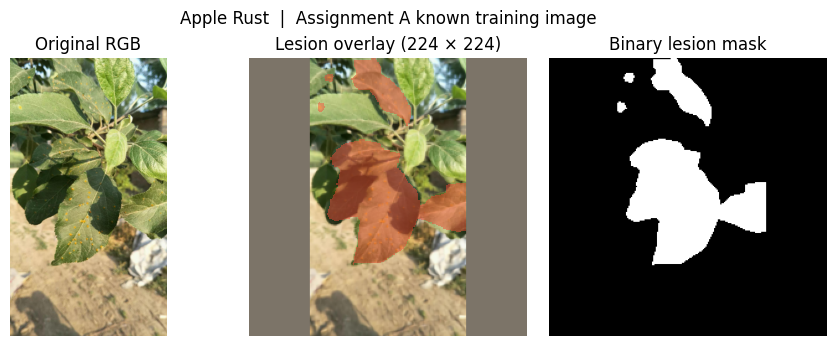

Example file: apple_rust_10.jpg


In [5]:
def prepare_image(image, mask=None, *, training=False, return_valid_region=False):
    """Resize the entire photo, applying the same geometry to an optional mask."""
    image = ImageOps.exif_transpose(image).convert("RGB")
    if mask is not None:
        if image.size != mask.size:
            raise ValueError(f"Photo size {image.size} after EXIF correction differs from mask size {mask.size}")
        mask = mask.convert("L").point(lambda value: 255 if value > 0 else 0)

    scale = IMAGE_SIZE / max(image.size)
    size = tuple(max(1, round(value * scale)) for value in image.size)
    image = image.resize(size, Image.Resampling.BILINEAR)
    if mask is not None:
        mask = mask.resize(size, Image.Resampling.NEAREST)

    if training:
        if random.random() < 0.5:
            image = ImageOps.mirror(image)
            if mask is not None:
                mask = ImageOps.mirror(mask)
        image = color_jitter(image)

    offset = tuple((IMAGE_SIZE - value) // 2 for value in size)
    canvas = Image.new("RGB", (IMAGE_SIZE, IMAGE_SIZE), pad_color)
    canvas.paste(image, offset)
    mask_canvas = None
    if mask is not None:
        mask_canvas = Image.new("L", canvas.size)
        mask_canvas.paste(mask, offset)
    if return_valid_region:
        valid_region = Image.new("L", canvas.size)
        left, top = offset
        valid_region.paste(255, (left, top, left + size[0], top + size[1]))
        return canvas, mask_canvas, valid_region
    return canvas, mask_canvas


ASSIGNMENT = "A"
train_rows = [row for row in manifests[ASSIGNMENT] if row["split"] == "train"]
val_rows = [row for row in manifests[ASSIGNMENT] if row["split"] == "val" and row["role"] == "known"]
preview_row = train_rows[0]

with Image.open(preview_row["image_path"]) as image, Image.open(preview_row["mask_path"]) as mask:
    original = ImageOps.exif_transpose(image).convert("RGB")
    prepared, binary_mask = prepare_image(image, mask)

mask_pixels = np.asarray(binary_mask)
if not np.any(mask_pixels):
    raise ValueError("The displayed mask has no lesion pixels after preprocessing")

fig, axes = plt.subplots(1, 3, figsize=(9, 3.35), layout="constrained")
axes[0].imshow(original)
axes[0].set_title("Original RGB")
axes[1].imshow(prepared)
axes[1].imshow(
    np.ma.masked_where(mask_pixels == 0, mask_pixels),
    cmap=ListedColormap(["#f64b39"]),
    alpha=0.47,
    vmin=0,
    vmax=255,
)
axes[1].set_title(f"Lesion overlay ({IMAGE_SIZE} × {IMAGE_SIZE})")
axes[2].imshow(mask_pixels, cmap="gray", vmin=0, vmax=255)
axes[2].set_title("Binary lesion mask")
for ax in axes:
    ax.set_axis_off()
fig.suptitle(f"{preview_row['class_name'].title()}  |  Assignment {ASSIGNMENT} known training image")
plt.show()
print(f"Example file: {preview_row['image_path'].name}")

## 4. Train and validate the baseline

Fine-tune all layers of an ImageNet-pretrained ResNet-18 with a new classification head for the 25 known classes in assignment A. Use cross-entropy and AdamW for 20 epochs, with an initial learning rate of 0.0003 and cosine decay.

Record validation accuracy and macro-F1 after each epoch. Macro-F1 weights each class equally. Save the checkpoint with the highest macro-F1 on the known validation images.

The fixed class order follows ascending original class IDs. All 25 known classes have validation support. A zero F1 denominator contributes zero to the macro average. The validation comparison below uses the saved checkpoints for the matched pilot.

In [6]:
class KnownImageDataset(Dataset):
    def __init__(self, rows, *, training=False):
        self.rows = rows
        self.training = training

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, index):
        row = self.rows[index]
        with Image.open(row["image_path"]) as image:
            rgb, _ = prepare_image(image, training=self.training)
        tensor = TF.normalize(TF.to_tensor(rgb), image_mean, image_std)
        return tensor, row["target"]


BATCH_SIZE = 32
LEARNING_RATE = 3e-4
WEIGHT_DECAY = 1e-4
EPOCHS = 20
MIN_LEARNING_RATE = 1e-6

random.seed(SEED)
torch.manual_seed(SEED)

train_loader = DataLoader(
    KnownImageDataset(train_rows, training=True),
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=torch.Generator().manual_seed(SEED),
    num_workers=0,
)
val_loader = DataLoader(KnownImageDataset(val_rows), batch_size=BATCH_SIZE, num_workers=0)

n_classes = len(class_names[ASSIGNMENT])
model = resnet18(weights=WEIGHTS)
model.fc = nn.Linear(model.fc.in_features, n_classes)
model.to(DEVICE)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=EPOCHS, eta_min=MIN_LEARNING_RATE
)
print(f"Assignment {ASSIGNMENT}, seed {SEED}, batch {BATCH_SIZE}, {EPOCHS} epochs, AdamW initial lr={LEARNING_RATE:g}")
print(f"Training: {len(train_rows):,} known images; validation: {len(val_rows):,} known images")

Assignment A, seed 42, batch 32, 20 epochs, AdamW initial lr=0.0003
Training: 1,666 known images; validation: 278 known images


In [7]:
def train_epoch():
    model.train()
    loss_sum = 0.0
    n_images = 0
    for images, labels in train_loader:
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        optimizer.zero_grad(set_to_none=True)
        loss = criterion(model(images), labels)
        loss.backward()
        optimizer.step()
        n_images += labels.numel()
        loss_sum += loss.item() * labels.numel()
    return loss_sum / n_images


@torch.inference_mode()
def validate_known(classifier):
    classifier.eval()
    confusion = torch.zeros((n_classes, n_classes), dtype=torch.int64)
    loss_sum = 0.0
    for images, labels in val_loader:
        logits = classifier(images.to(DEVICE))
        loss_sum += criterion(logits, labels.to(DEVICE)).item() * labels.numel()
        predicted = logits.argmax(dim=1).cpu()
        counts = torch.bincount(labels * n_classes + predicted, minlength=n_classes ** 2)
        confusion += counts.reshape(n_classes, n_classes)

    true_positives = confusion.diag()
    # F1 per class = 2*TP / (true support + predicted support).
    f1_denominator = confusion.sum(dim=1) + confusion.sum(dim=0)
    macro_f1 = (2 * true_positives / f1_denominator.clamp_min(1)).mean().item()
    accuracy = true_positives.sum().item() / len(val_rows)
    return loss_sum / len(val_rows), macro_f1, accuracy


start = time.perf_counter()
history = []
best_result = None
best_state = None
for epoch in range(1, EPOCHS + 1):
    current_lr = optimizer.param_groups[0]["lr"]
    train_loss = train_epoch()
    val_loss, val_macro_f1, val_accuracy = validate_known(model)
    scheduler.step()

    result = {
        "epoch": epoch,
        "learning_rate": current_lr,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "val_macro_f1": val_macro_f1,
        "val_accuracy": val_accuracy,
    }
    history.append(result)
    if best_result is None or val_macro_f1 > best_result["val_macro_f1"]:
        best_result = result
        best_state = {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | train loss {train_loss:.4f} | val loss {val_loss:.4f} | "
        f"val Macro-F1 {val_macro_f1:.4f} | val accuracy {val_accuracy:.2%}",
        flush=True,
    )

elapsed_seconds = time.perf_counter() - start
model.load_state_dict(best_state)
checkpoint_path = manifest_dir / f"baseline_{ASSIGNMENT}_seed{SEED}_lr{LEARNING_RATE:g}_epochs{EPOCHS}.pt"
checkpoint = {
    "architecture": "resnet18",
    "pretrained_weights": WEIGHTS.name,
    "assignment": ASSIGNMENT,
    "seed": SEED,
    "known_class_order": class_names[ASSIGNMENT],
    "manifest_sha256": hashlib.sha256(manifest_path.read_bytes()).hexdigest(),
    "batch_size": BATCH_SIZE,
    "optimizer": "AdamW",
    "initial_learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "scheduler": "CosineAnnealingLR",
    "minimum_learning_rate": MIN_LEARNING_RATE,
    "history": history,
    "selected_epoch": best_result["epoch"],
    "elapsed_seconds": elapsed_seconds,
    "model_state_dict": best_state,
}
# Replace the checkpoint only after writing the complete file.
with tempfile.NamedTemporaryFile(dir=manifest_dir, suffix=".tmp", delete=False) as temporary:
    temporary_path = Path(temporary.name)
try:
    torch.save(checkpoint, temporary_path)
    temporary_path.replace(checkpoint_path)
finally:
    temporary_path.unlink(missing_ok=True)

print(f"Selected epoch by known validation Macro-F1: {best_result['epoch']}")
print(f"Selected known validation Macro-F1: {best_result['val_macro_f1']:.4f}")
print(f"Selected known validation accuracy: {best_result['val_accuracy']:.2%}")
print(f"Training plus validation: {elapsed_seconds:.1f} seconds")
print(f"Saved checkpoint: {checkpoint_path.as_posix()}")

Epoch 01/20 | train loss 1.6508 | val loss 1.0096 | val Macro-F1 0.6114 | val accuracy 66.91%


Epoch 02/20 | train loss 0.6527 | val loss 1.0698 | val Macro-F1 0.6443 | val accuracy 67.27%


Epoch 03/20 | train loss 0.3729 | val loss 0.9960 | val Macro-F1 0.6591 | val accuracy 68.35%


Epoch 04/20 | train loss 0.2877 | val loss 1.0889 | val Macro-F1 0.6249 | val accuracy 66.19%


Epoch 05/20 | train loss 0.2281 | val loss 0.8898 | val Macro-F1 0.6942 | val accuracy 72.30%


Epoch 06/20 | train loss 0.1331 | val loss 0.9660 | val Macro-F1 0.6778 | val accuracy 71.58%


... (11 outputs left out)

Epoch 18/20 | train loss 0.0128 | val loss 0.7144 | val Macro-F1 0.7565 | val accuracy 79.86%


Epoch 19/20 | train loss 0.0121 | val loss 0.7499 | val Macro-F1 0.7451 | val accuracy 79.14%


Epoch 20/20 | train loss 0.0106 | val loss 0.7506 | val Macro-F1 0.7498 | val accuracy 78.78%


Selected epoch by known validation Macro-F1: 15
Selected known validation Macro-F1: 0.7661
Selected known validation accuracy: 78.78%
Training plus validation: 503.6 seconds
Saved checkpoint: artifacts/baseline_A_seed42_lr0.0003_epochs20.pt


## 5. Learning curves

The dashed line marks the epoch selected by known validation macro-F1. Accuracy and macro-F1 are reported for the same checkpoint.

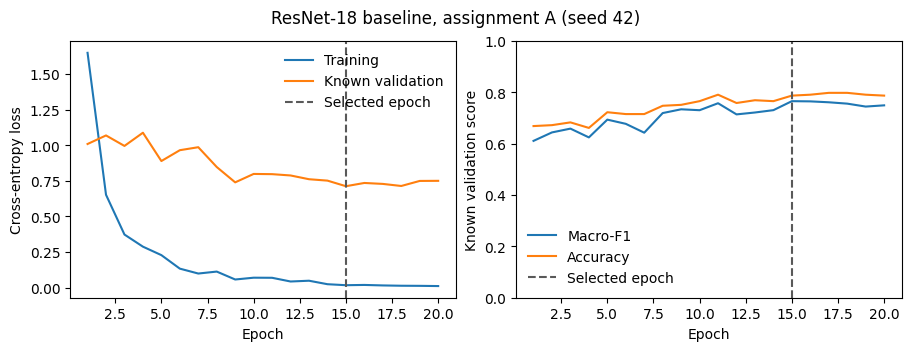

In [8]:
epochs = [row["epoch"] for row in history]
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4), layout="constrained")
axes[0].plot(epochs, [row["train_loss"] for row in history], label="Training")
axes[0].plot(epochs, [row["val_loss"] for row in history], label="Known validation")
axes[0].set_ylabel("Cross-entropy loss")
axes[1].plot(epochs, [row["val_macro_f1"] for row in history], label="Macro-F1")
axes[1].plot(epochs, [row["val_accuracy"] for row in history], label="Accuracy")
axes[1].set_ylabel("Known validation score")
axes[1].set_ylim(0, 1)

for ax in axes:
    ax.axvline(best_result["epoch"], color="0.35", linestyle="--", label="Selected epoch")
    ax.set_xlabel("Epoch")
    ax.legend(frameon=False)
fig.suptitle(f"ResNet-18 baseline, assignment {ASSIGNMENT} (seed {SEED})")
plt.show()

## 6. Lesion-supervised ResNet-18

A small convolutional head uses the shared layer-2 feature map to predict lesion pixels. The model starts from the same ImageNet weights and seed as the baseline. Both runs share the image preprocessing, augmentation draws, sample order, optimizer schedule and training budget. Training pairs each known-class RGB image with its binary lesion mask. Padding is excluded from the binary cross-entropy and soft Dice losses.

The objective is classification cross-entropy plus 0.25 times the mean of the two mask losses. The auxiliary target may encourage representations of disease regions. This effect may depend on the quality of lesion annotations and the visibility of symptoms. Validation classification uses RGB input and the classification head. Checkpoint selection again uses known validation macro-F1.

In [9]:
from torch.nn import functional as F


class LesionTrainingDataset(KnownImageDataset):
    """Use binary masks only for the allowed known-class training rows."""

    def __init__(self, rows):
        if any(row["split"] != "train" or row["role"] != "known" for row in rows):
            raise ValueError("Lesion supervision requires known-class training rows.")
        super().__init__(rows, training=True)

    def __getitem__(self, index):
        row = self.rows[index]
        with Image.open(row["image_path"]) as image, Image.open(row["mask_path"]) as mask:
            rgb, binary, valid = prepare_image(image, mask, training=True, return_valid_region=True)
        image_tensor = TF.normalize(TF.to_tensor(rgb), image_mean, image_std)
        return image_tensor, row["target"], TF.to_tensor(binary), TF.to_tensor(valid)


class LesionSupervisedResNet18(nn.Module):
    def __init__(self, num_classes, weights=None):
        super().__init__()
        self.classifier = resnet18(weights=weights)
        self.classifier.fc = nn.Linear(self.classifier.fc.in_features, num_classes)
        # Keep auxiliary initialization out of the classifier and augmentation RNG stream.
        with torch.random.fork_rng(devices=[]):
            self.lesion_head = nn.Sequential(
                nn.Conv2d(128, 32, kernel_size=3, padding=1),
                nn.ReLU(),
                nn.Conv2d(32, 1, kernel_size=1),
            )

    def forward(self, images, *, predict_lesions=False):
        if not predict_lesions:
            return self.classifier(images)

        backbone = self.classifier
        features = backbone.maxpool(backbone.relu(backbone.bn1(backbone.conv1(images))))
        lesion_features = backbone.layer2(backbone.layer1(features))
        features = backbone.layer4(backbone.layer3(lesion_features))
        logits = backbone.fc(torch.flatten(backbone.avgpool(features), 1))
        lesion_logits = F.interpolate(
            self.lesion_head(lesion_features),
            size=images.shape[-2:],
            mode="bilinear",
            align_corners=False,
        )
        return logits, lesion_logits


def lesion_loss(logits, target, valid_region):
    """Average per-image BCE and soft Dice loss over the unpadded region."""
    axes = (1, 2, 3)
    pixel_loss = F.binary_cross_entropy_with_logits(logits, target, reduction="none")
    bce = (pixel_loss * valid_region).sum(axes) / valid_region.sum(axes).clamp_min(1)
    probability = logits.sigmoid() * valid_region
    target = target * valid_region
    intersection = (probability * target).sum(axes)
    dice = (2 * intersection + 1) / (probability.sum(axes) + target.sum(axes) + 1)
    return 0.5 * (bce.mean() + (1 - dice).mean())

In [10]:
LESION_WEIGHT = 0.25

# Restart from the same seed and generic weights used for the baseline.
random.seed(SEED)
torch.manual_seed(SEED)
lesion_train_loader = DataLoader(
    LesionTrainingDataset(train_rows),
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=torch.Generator().manual_seed(SEED),
    num_workers=0,
)
lesion_model = LesionSupervisedResNet18(n_classes, weights=WEIGHTS).to(DEVICE)
lesion_optimizer = torch.optim.AdamW(
    lesion_model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY
)
lesion_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    lesion_optimizer, T_max=EPOCHS, eta_min=MIN_LEARNING_RATE
)

lesion_history = []
best_lesion_result = None
best_lesion_state = None
lesion_start = time.perf_counter()
for epoch in range(1, EPOCHS + 1):
    lesion_model.train()
    n_images = 0
    classification_loss_sum = 0.0
    auxiliary_loss_sum = 0.0
    for images, targets, masks, valid in lesion_train_loader:
        images, targets = images.to(DEVICE), targets.to(DEVICE)
        masks, valid = masks.to(DEVICE), valid.to(DEVICE)
        lesion_optimizer.zero_grad(set_to_none=True)
        logits, mask_logits = lesion_model(images, predict_lesions=True)
        classification_loss = criterion(logits, targets)
        auxiliary_loss = lesion_loss(mask_logits, masks, valid)
        (classification_loss + LESION_WEIGHT * auxiliary_loss).backward()
        lesion_optimizer.step()
        n_images += targets.numel()
        classification_loss_sum += classification_loss.item() * targets.numel()
        auxiliary_loss_sum += auxiliary_loss.item() * targets.numel()

    val_loss, val_f1, val_accuracy = validate_known(lesion_model)
    lesion_result = {
        "epoch": epoch,
        "learning_rate": lesion_optimizer.param_groups[0]["lr"],
        "train_classification_loss": classification_loss_sum / n_images,
        "train_lesion_loss": auxiliary_loss_sum / n_images,
        "val_loss": val_loss,
        "val_macro_f1": val_f1,
        "val_accuracy": val_accuracy,
    }
    lesion_history.append(lesion_result)
    if best_lesion_result is None or val_f1 > best_lesion_result["val_macro_f1"]:
        best_lesion_result = lesion_result
        best_lesion_state = {
            key: value.detach().cpu().clone() for key, value in lesion_model.state_dict().items()
        }
    lesion_scheduler.step()
    print(
        f"Lesion epoch {epoch:02d}/{EPOCHS} | classification loss {lesion_result['train_classification_loss']:.4f} | "
        f"lesion loss {lesion_result['train_lesion_loss']:.4f} | "
        f"val Macro-F1 {val_f1:.4f} | val accuracy {val_accuracy:.2%}",
        flush=True,
    )

lesion_elapsed = time.perf_counter() - lesion_start
lesion_model.load_state_dict(best_lesion_state)
lesion_checkpoint_path = (
    manifest_dir / f"lesion_{ASSIGNMENT}_seed{SEED}_lr{LEARNING_RATE:g}_epochs{EPOCHS}.pt"
)
lesion_checkpoint = {
    "architecture": "resnet18_with_layer2_lesion_head",
    "pretrained_weights": WEIGHTS.name,
    "assignment": ASSIGNMENT,
    "seed": SEED,
    "known_class_order": class_names[ASSIGNMENT],
    "manifest_sha256": hashlib.sha256(manifest_path.read_bytes()).hexdigest(),
    "batch_size": BATCH_SIZE,
    "optimizer": "AdamW",
    "initial_learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "scheduler": "CosineAnnealingLR",
    "minimum_learning_rate": MIN_LEARNING_RATE,
    "lesion_loss_weight": LESION_WEIGHT,
    "history": lesion_history,
    "selected_epoch": best_lesion_result["epoch"],
    "elapsed_seconds": lesion_elapsed,
    "model_state_dict": best_lesion_state,
}
with tempfile.NamedTemporaryFile(dir=manifest_dir, suffix=".tmp", delete=False) as temporary:
    temporary_path = Path(temporary.name)
try:
    torch.save(lesion_checkpoint, temporary_path)
    temporary_path.replace(lesion_checkpoint_path)
finally:
    temporary_path.unlink(missing_ok=True)
print(
    f"Selected lesion epoch {best_lesion_result['epoch']} | "
    f"val Macro-F1 {best_lesion_result['val_macro_f1']:.4f} | "
    f"val accuracy {best_lesion_result['val_accuracy']:.2%}"
)
print(f"Training plus validation: {lesion_elapsed:.1f} seconds")
print(f"Saved checkpoint: {lesion_checkpoint_path.as_posix()}")

Lesion epoch 01/20 | classification loss 1.6507 | lesion loss 0.6579 | val Macro-F1 0.6337 | val accuracy 68.35%


Lesion epoch 02/20 | classification loss 0.6500 | lesion loss 0.6057 | val Macro-F1 0.6876 | val accuracy 70.14%


Lesion epoch 03/20 | classification loss 0.3715 | lesion loss 0.5764 | val Macro-F1 0.6965 | val accuracy 72.66%


Lesion epoch 04/20 | classification loss 0.2802 | lesion loss 0.5599 | val Macro-F1 0.6663 | val accuracy 68.35%


Lesion epoch 05/20 | classification loss 0.2058 | lesion loss 0.5504 | val Macro-F1 0.6974 | val accuracy 72.66%


Lesion epoch 06/20 | classification loss 0.1455 | lesion loss 0.5428 | val Macro-F1 0.7121 | val accuracy 71.94%


... (11 outputs left out)

Lesion epoch 18/20 | classification loss 0.0119 | lesion loss 0.4950 | val Macro-F1 0.7684 | val accuracy 80.22%


Lesion epoch 19/20 | classification loss 0.0129 | lesion loss 0.4924 | val Macro-F1 0.7312 | val accuracy 78.78%


Lesion epoch 20/20 | classification loss 0.0098 | lesion loss 0.4939 | val Macro-F1 0.7497 | val accuracy 78.42%


Selected lesion epoch 17 | val Macro-F1 0.7825 | val accuracy 81.65%
Training plus validation: 554.5 seconds
Saved checkpoint: artifacts/lesion_A_seed42_lr0.0003_epochs20.pt


## 7. Open-set validation comparison

The two selected checkpoints classify the same RGB validation images. Each score increases with evidence for a known class. Maximum softmax probability uses the largest probability. Maximum logit uses the largest raw logit. Negative energy is log-sum-exp of the logits at temperature 1.

The OSCR curve plots the rate of correct and accepted known predictions against the rate of false accepts among unknown images. AUOSCR integrates the curve across the full false-acceptance range. Unknown AUROC measures ranking with unknown as the positive class and the negated score. Each fixed operating point uses the largest threshold that accepts at least 95% of the known validation images, counting tied scores together.

This pilot reports all three scores. Familiar-host unknowns address the research question, and citrus provides an unfamiliar-host validation control. Results cover one paired seed on assignment A. The primary score and final configurations will be selected using the full validation experiment before test evaluation.


In [11]:
class ValidationImages(KnownImageDataset):
    def __getitem__(self, index):
        image, _ = super().__getitem__(index)
        return image


pilot_validation_rows = [
    row for row in manifests[ASSIGNMENT] if row["split"] == "val"
]
pilot_loader = DataLoader(
    ValidationImages(pilot_validation_rows), batch_size=BATCH_SIZE, num_workers=0
)
baseline_path = manifest_dir / f"baseline_{ASSIGNMENT}_seed{SEED}_lr{LEARNING_RATE:g}_epochs{EPOCHS}.pt"
baseline_network = resnet18(weights=None)
baseline_network.fc = nn.Linear(baseline_network.fc.in_features, n_classes)
networks = {"Baseline": (baseline_network, baseline_path), "Lesion": (lesion_model, lesion_checkpoint_path)}
validation_logits = {}
pilot_checkpoints = {}
manifest_hash = hashlib.sha256(manifest_path.read_bytes()).hexdigest()
for label, (network, path) in networks.items():
    saved = torch.load(path, map_location="cpu", weights_only=True)
    expected = {
        "manifest_sha256": manifest_hash,
        "assignment": ASSIGNMENT,
        "seed": SEED,
        "known_class_order": class_names[ASSIGNMENT],
        "pretrained_weights": WEIGHTS.name,
        "batch_size": BATCH_SIZE,
        "optimizer": "AdamW",
        "initial_learning_rate": LEARNING_RATE,
        "weight_decay": WEIGHT_DECAY,
        "scheduler": "CosineAnnealingLR",
        "minimum_learning_rate": MIN_LEARNING_RATE,
    }
    if any(saved[key] != value for key, value in expected.items()) or len(saved["history"]) != EPOCHS:
        raise ValueError(f"{path.name} does not match the pilot training settings.")
    selected_epoch = max(saved["history"], key=lambda row: row["val_macro_f1"])["epoch"]
    if saved["selected_epoch"] != selected_epoch:
        raise ValueError(f"{path.name} does not use its best known-validation Macro-F1 epoch.")
    network.load_state_dict(saved["model_state_dict"])
    network.to(DEVICE).eval()
    with torch.inference_mode():
        validation_logits[label] = torch.cat([network(images.to(DEVICE)).cpu() for images in pilot_loader])
    pilot_checkpoints[label] = {
        "path": path.as_posix(),
        "selected_epoch": selected_epoch,
        "known_validation_at_selection": saved["history"][selected_epoch - 1],
    }
    print(f"{label}: epoch {selected_epoch}, {len(validation_logits[label])} RGB validation predictions")

Baseline: epoch 15, 374 RGB validation predictions


Lesion: epoch 17, 374 RGB validation predictions


In [12]:
import math

import numpy as np
import torch


def known_class_metrics(logits, targets):
    """Accuracy and macro-F1 over the fixed known label set before rejection."""
    predicted = logits.argmax(dim=1).numpy()
    num_classes = logits.shape[1]
    confusion = np.bincount(
        targets * num_classes + predicted, minlength=num_classes**2
    ).reshape(num_classes, num_classes)
    support = confusion.sum(axis=1)
    predicted_count = confusion.sum(axis=0)
    true_positive = np.diag(confusion)
    denominator = support + predicted_count
    per_class_f1 = np.divide(
        2 * true_positive,
        denominator,
        out=np.zeros(num_classes, dtype=float),
        where=denominator > 0,
    )
    correct = predicted == targets
    return {
        "known_accuracy": float(correct.mean()),
        "known_macro_f1": float(per_class_f1.mean()),
        "known_correct_count": int(correct.sum()),
    }, correct


def known_score_vectors(logits):
    """Higher values indicate stronger evidence for a known class."""
    return {
        "MSP": logits.softmax(dim=1).amax(dim=1).numpy(),
        "MaxLogit": logits.amax(dim=1).numpy(),
        "Negative energy": logits.logsumexp(dim=1).numpy(),
    }


def threshold_for_known_acceptance(known_scores, acceptance=0.95):
    """Choose the largest observed threshold accepting at least ceil(p*n) known images."""
    minimum_accepted = math.ceil(acceptance * len(known_scores))
    return float(np.sort(known_scores)[-minimum_accepted])


def open_set_curves(known_scores, known_correct, unknown_scores):
    """Sweep grouped thresholds with score >= threshold and return the OSCR curve and areas."""
    num_known, num_unknown = len(known_scores), len(unknown_scores)
    if min(num_known, num_unknown) == 0:
        raise ValueError("Open-set evaluation requires known and unknown images.")

    scores = np.concatenate((known_scores, unknown_scores))
    is_known = np.concatenate((np.ones(num_known, dtype=bool), np.zeros(num_unknown, dtype=bool)))
    is_correct_known = np.concatenate((known_correct, np.zeros(num_unknown, dtype=bool)))
    order = np.argsort(-scores, kind="stable")
    sorted_scores = scores[order]
    # Every tied score enters at once when the threshold reaches that score.
    group_end = np.r_[np.flatnonzero(sorted_scores[:-1] != sorted_scores[1:]), len(scores) - 1]
    unknown_accepted = np.r_[0, np.cumsum(~is_known[order])[group_end]] / num_unknown
    known_accepted = np.r_[0, np.cumsum(is_known[order])[group_end]] / num_known
    correct_known_accepted = np.r_[0, np.cumsum(is_correct_known[order])[group_end]] / num_known

    # Unknown-positive AUROC with score -s equals known-positive AUROC with s:
    # both measure P(s_known > s_unknown) + 0.5 * P(s_known == s_unknown).
    widths = np.diff(unknown_accepted)
    auoscr = float(np.sum(widths * (correct_known_accepted[:-1] + correct_known_accepted[1:]) / 2))
    unknown_auroc = float(np.sum(widths * (known_accepted[:-1] + known_accepted[1:]) / 2))
    return unknown_accepted, correct_known_accepted, auoscr, unknown_auroc

Known validation: **278** images. Familiar-host unknown: **54** images. Citrus unknown: **42** images.

| Model | Known accuracy | Known macro-F1 | Correct known predictions |
|---|---:|---:|---:|
| Baseline | 78.78% | 0.7661 | 219/278 |
| Lesion | 81.65% | 0.7825 | 227/278 |

| Unknown group | Score | Baseline AUOSCR | Lesion AUOSCR | Lesion − baseline | Baseline AUROC | Lesion AUROC |
|---|---|---:|---:|---:|---:|---:|
| Familiar-host unknown | MSP | 0.5937 | 0.6091 | +0.0154 | 0.6733 | 0.6888 |
| Familiar-host unknown | MaxLogit | 0.6078 | 0.6274 | +0.0197 | 0.7023 | 0.7140 |
| Familiar-host unknown | Negative energy | 0.6099 | 0.6316 | +0.0216 | 0.7088 | 0.7205 |
| Citrus unknown | MSP | 0.6274 | 0.6819 | +0.0546 | 0.7073 | 0.7895 |
| Citrus unknown | MaxLogit | 0.6349 | 0.6886 | +0.0537 | 0.7291 | 0.7929 |
| Citrus unknown | Negative energy | 0.6383 | 0.6872 | +0.0489 | 0.7361 | 0.7904 |

| Model | Score | Threshold | Known accepted | Known correct and accepted | Familiar unknown accepted | Citrus unknown accepted |
|---|---|---:|---:|---:|---:|---:|
| Baseline | MSP | 0.414834 | 95.32% | 77.34% | 96.30% | 95.24% |
| Baseline | MaxLogit | 3.40126 | 95.32% | 77.70% | 88.89% | 90.48% |
| Baseline | Negative energy | 4.1503 | 95.32% | 77.34% | 87.04% | 90.48% |
| Lesion | MSP | 0.486003 | 95.32% | 78.78% | 83.33% | 71.43% |
| Lesion | MaxLogit | 3.62477 | 95.32% | 79.50% | 77.78% | 78.57% |
| Lesion | Negative energy | 4.16812 | 95.32% | 79.14% | 79.63% | 83.33% |

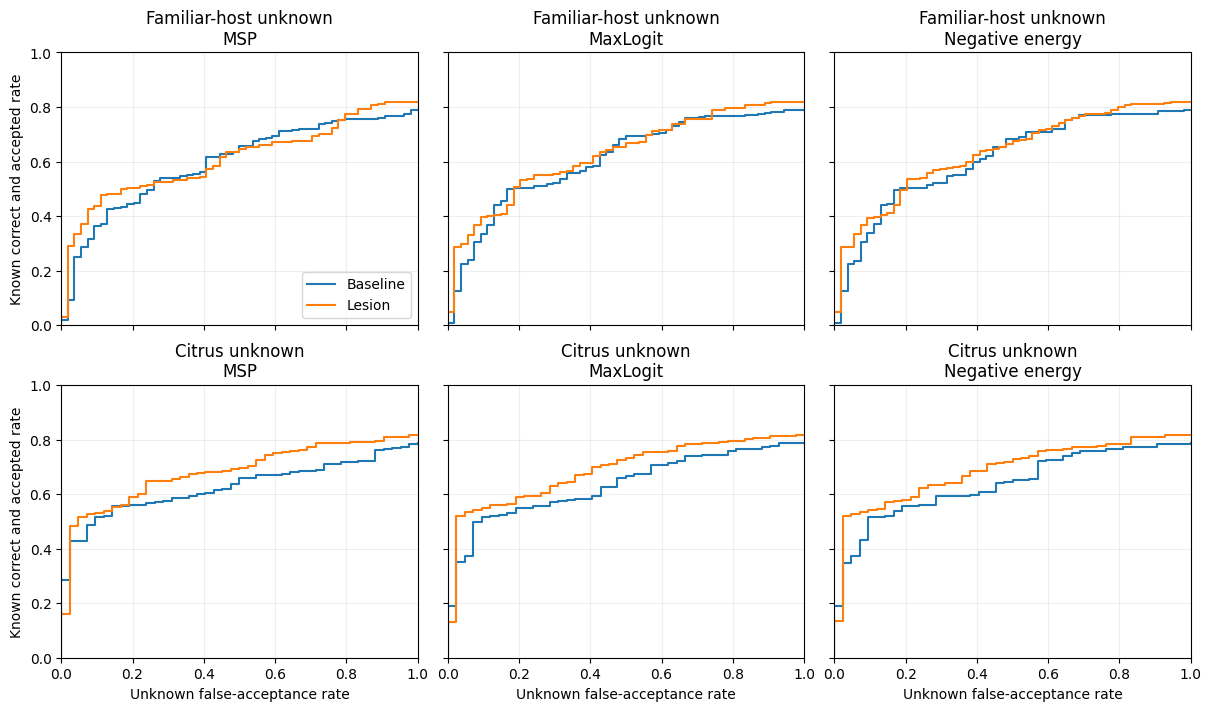

In [13]:
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

validation_roles = np.asarray([row["role"] for row in pilot_validation_rows])
known_mask = validation_roles == "known"
unknown_groups = {
    "familiar_dev": "Familiar-host unknown",
    "unfamiliar_dev": "Citrus unknown",
}
validation_counts = {
    role: int(np.sum(validation_roles == role))
    for role in ("known", *unknown_groups)
}
if sum(validation_counts.values()) != len(pilot_validation_rows) or min(validation_counts.values()) == 0:
    raise ValueError("Expected known, familiar-host unknown and citrus validation images.")

known_targets = np.asarray(
    [row["target"] for row in pilot_validation_rows if row["role"] == "known"],
    dtype=np.int64,
)
if np.any((known_targets < 0) | (known_targets >= 25)):
    raise ValueError("Known validation targets must be in the fixed 25-class label set.")

pilot_results = {"validation_counts": validation_counts, "models": {}}
pilot_curves = {}
for model_name in ("Baseline", "Lesion"):
    logits = validation_logits[model_name].detach().cpu()
    if logits.shape != (len(pilot_validation_rows), 25) or not torch.isfinite(logits).all():
        raise ValueError(f"{model_name} logits must be finite and aligned to the validation rows.")

    known_metrics, known_correct = known_class_metrics(logits[known_mask], known_targets)
    model_metrics = dict(known_metrics, scores={})
    pilot_results["models"][model_name] = model_metrics
    for score_name, score_vector in known_score_vectors(logits).items():
        known_scores = score_vector[known_mask]
        threshold = threshold_for_known_acceptance(known_scores)
        known_accepted = known_scores >= threshold
        score_metrics = {
            "threshold": threshold,
            "known_acceptance": float(known_accepted.mean()),
            "known_correct_acceptance": float((known_accepted & known_correct).mean()),
            "known_accepted_count": int(known_accepted.sum()),
            "groups": {},
        }
        model_metrics["scores"][score_name] = score_metrics
        for role in unknown_groups:
            unknown_scores = score_vector[validation_roles == role]
            fpr, ccr, auoscr, auroc = open_set_curves(known_scores, known_correct, unknown_scores)
            unknown_accepted = unknown_scores >= threshold
            score_metrics["groups"][role] = {
                "auoscr": auoscr,
                "unknown_auroc": auroc,
                "unknown_false_acceptance": float(unknown_accepted.mean()),
                "unknown_accepted_count": int(unknown_accepted.sum()),
            }
            pilot_curves[model_name, score_name, role] = (fpr, ccr)

models = pilot_results["models"]
display(Markdown(
    f"Known validation: **{validation_counts['known']}** images. Familiar-host unknown: "
    f"**{validation_counts['familiar_dev']}** images. Citrus unknown: "
    f"**{validation_counts['unfamiliar_dev']}** images."
))
known_table = [
    "| Model | Known accuracy | Known macro-F1 | Correct known predictions |",
    "|---|---:|---:|---:|",
]
for model_name, values in models.items():
    known_table.append(
        f"| {model_name} | {values['known_accuracy']:.2%} | {values['known_macro_f1']:.4f} "
        f"| {values['known_correct_count']}/{validation_counts['known']} |"
    )
display(Markdown("\n".join(known_table)))

comparison_table = [
    "| Unknown group | Score | Baseline AUOSCR | Lesion AUOSCR | Lesion − baseline | Baseline AUROC | Lesion AUROC |",
    "|---|---|---:|---:|---:|---:|---:|",
]
for role, label in unknown_groups.items():
    for score_name in models["Baseline"]["scores"]:
        baseline = models["Baseline"]["scores"][score_name]["groups"][role]
        lesion = models["Lesion"]["scores"][score_name]["groups"][role]
        comparison_table.append(
            f"| {label} | {score_name} | {baseline['auoscr']:.4f} | {lesion['auoscr']:.4f} "
            f"| {lesion['auoscr'] - baseline['auoscr']:+.4f} "
            f"| {baseline['unknown_auroc']:.4f} | {lesion['unknown_auroc']:.4f} |"
        )
display(Markdown("\n".join(comparison_table)))

operating_point_table = [
    "| Model | Score | Threshold | Known accepted | Known correct and accepted | Familiar unknown accepted | Citrus unknown accepted |",
    "|---|---|---:|---:|---:|---:|---:|",
]
for model_name, model_metrics in models.items():
    for score_name, values in model_metrics["scores"].items():
        operating_point_table.append(
            f"| {model_name} | {score_name} | {values['threshold']:.6g} "
            f"| {values['known_acceptance']:.2%} | {values['known_correct_acceptance']:.2%} "
            f"| {values['groups']['familiar_dev']['unknown_false_acceptance']:.2%} "
            f"| {values['groups']['unfamiliar_dev']['unknown_false_acceptance']:.2%} |"
        )
display(Markdown("\n".join(operating_point_table)))

fig, axes = plt.subplots(2, 3, figsize=(12, 7), sharex=True, sharey=True, constrained_layout=True)
for row_index, (role, label) in enumerate(unknown_groups.items()):
    for column_index, score_name in enumerate(models["Baseline"]["scores"]):
        ax = axes[row_index, column_index]
        for model_name in models:
            x, y = pilot_curves[model_name, score_name, role]
            ax.plot(x, y, label=model_name)
        ax.set_title(f"{label}\n{score_name}")
        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1)
        ax.grid(alpha=0.2)
        if column_index == 0:
            ax.set_ylabel("Known correct and accepted rate")
        if row_index == 1:
            ax.set_xlabel("Unknown false-acceptance rate")
axes[0, 0].legend(loc="lower right")
plt.show()

In [14]:
baseline_f1 = pilot_results["models"]["Baseline"]["known_macro_f1"]
lesion_f1 = pilot_results["models"]["Lesion"]["known_macro_f1"]
f1_difference = lesion_f1 - baseline_f1
known_tolerance = 0.02
for name, model_metrics in pilot_results["models"].items():
    selected = pilot_checkpoints[name]["known_validation_at_selection"]
    if abs(selected["val_macro_f1"] - model_metrics["known_macro_f1"]) > 1e-6:
        raise ValueError(f"{name} validation macro-F1 differs from its selected checkpoint.")
    if abs(selected["val_accuracy"] - model_metrics["known_accuracy"]) > 1e-6:
        raise ValueError(f"{name} validation accuracy differs from its selected checkpoint.")

pilot_results["pilot"] = {
    "assignment": ASSIGNMENT,
    "seed": SEED,
    "partition": "validation",
    "manifest_sha256": manifest_hash,
    "epochs": EPOCHS,
    "initial_learning_rate": LEARNING_RATE,
    "lesion_loss_weight": LESION_WEIGHT,
    "checkpoints": pilot_checkpoints,
    "lesion_minus_baseline_known_macro_f1": f1_difference,
    "within_known_macro_f1_tolerance": bool(f1_difference >= -known_tolerance),
}
pilot_path = manifest_dir / f"pilot_{ASSIGNMENT}_seed{SEED}_open_set_validation.json"
pilot_path.write_text(json.dumps(pilot_results, indent=2) + "\n", encoding="utf-8")
print(f"Known macro-F1 difference (lesion minus baseline): {f1_difference:+.4f}")
print(f"Within the 0.02 known macro-F1 tolerance: {f1_difference >= -known_tolerance}")
print(f"Saved pilot validation results: {pilot_path.as_posix()}")

Known macro-F1 difference (lesion minus baseline): +0.0164
Within the 0.02 known macro-F1 tolerance: True
Saved pilot validation results: artifacts/pilot_A_seed42_open_set_validation.json


## 8. Pilot observations

Known validation accuracy increased from 78.78% to 81.65%, and macro-F1 increased from 0.7661 to 0.7825. Familiar-host AUOSCR increased under all three scoring rules.

For negative energy, familiar-host AUOSCR increased from 0.6099 to 0.6316, and unknown AUROC increased from 0.7088 to 0.7205. At the calibrated operating point, each model accepts 265 of 278 known images. The baseline accepts 47 of 54 unfamiliar disease images on familiar hosts, and the lesion model accepts 43. This leaves substantial unknown false acceptance even with lesion supervision.

The AUOSCR difference reflects both correct known classification and unknown rejection. These are assignment-A, seed-42 validation observations. Variation across seeds and assignments remains to be measured before assessing the full hypothesis.
